### K means Clustering


import libs and load data

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

load file 

In [34]:
df= pd.read_csv(r"C:\Users\Nandini\OneDrive\Desktop\ml algos\k_means\Credit Card Customer Data.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum())
display(df.head())

Shape: (660, 7)
Missing values:
 Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


### Select customer features and scale them

In [35]:
features = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

X = df[features]
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

Although this CSV currently has no missing values, the median imputer will handle them if you use a version of the data that does. Scaling matters because K-means compares distances, and credit limits have a much larger numeric range than the other features.

### Calculate and plot inertia for the elbow method

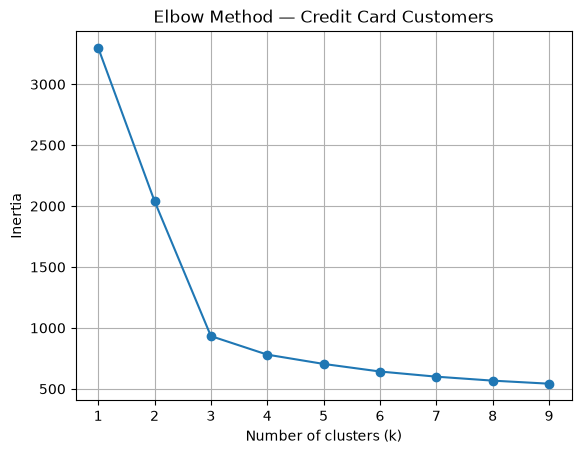

In [36]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(1, 10)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method — Credit Card Customers")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Choose a k near the bend in the graph, where adding more clusters starts to reduce inertia less sharply.
### so we choose k=3.

Fit K-means using your chosen number of clusters

In [37]:
chosen_k = 3
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)
print(df["Cluster"].value_counts().sort_index())

Cluster
0    386
1     50
2    224
Name: count, dtype: int64


Summarize the customer groups

In [38]:
cluster_summary = df.groupby("Cluster")[features].mean().round(2)
display(cluster_summary)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33782.38,5.52,3.49,0.98,2.00
1,141040.00,8.74,0.60,10.90,1.08
2,12174.11,2.41,0.93,3.55,6.87


### Plot two features by cluster

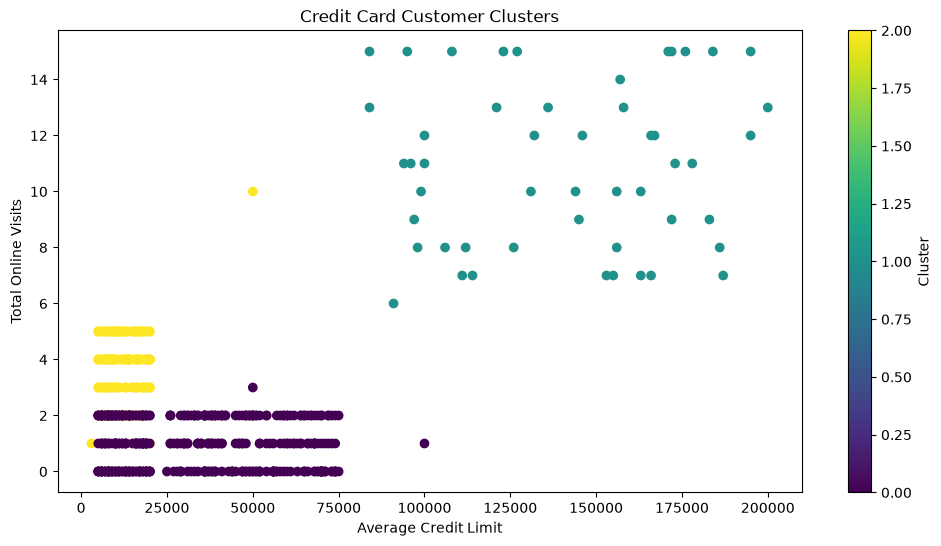

In [42]:
plt.figure(figsize=(12, 6))
plt.scatter(
    df["Avg_Credit_Limit"],
    df["Total_visits_online"],
    c=df["Cluster"]
)
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Online Visits")
plt.title("Credit Card Customer Clusters")
plt.colorbar(label="Cluster")
plt.show()

The plot suggests three customer segments:
- Cluster 0 (purple): Mostly lower to mid credit limits, with few online visits-generally 0-3.
- Cluster 1 (teal): Higher credit limits and frequent online visits, often around 6-15.
- Cluster 2 (yellow): Mostly lower credit limits and a moderate number of online visits, around 3-5. One yellow point is an exception, with about 50,000 credit limit and 10 online visits.